In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('CIC-IoT-IDAD-Dataset-2024-balanced_dataset.csv')

In [3]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,291959,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1955.754061,30.826246,36494.875,57448.362362,147841.0,1.0,274175.0,68543.75,78699.844123,147841.0,533.0,125035.0,41678.333333,72187.258857,125033.0,1.0,0,0,0,0,168,136,17.125692,13.700554,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
1,6,291320,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,885.624056,30.893862,36415.000,57258.196618,147430.0,1.0,273612.0,68403.00,78399.041674,147430.0,635.0,124749.0,41583.000000,72022.136680,124747.0,1.0,0,0,0,0,168,136,17.163257,13.730606,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
2,6,292739,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1950.542975,30.744110,36592.375,57576.745941,148188.0,1.0,274836.0,68709.00,78902.837114,148188.0,557.0,125341.0,41780.333333,72363.928040,125339.0,1.0,0,0,0,0,168,136,17.080061,13.664049,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
3,6,292398,5,4,251.0,7.0,251.0,0.0,50.2,112.250612,7.0,0.0,1.75,3.5,882.358976,30.779964,36549.750,57456.509783,147881.0,1.0,274642.0,68660.50,78638.025206,147881.0,714.0,125299.0,41766.333333,72339.679328,125297.0,1.0,0,0,0,0,168,136,17.099980,13.679984,0.0,251.0,25.8,79.157789,6265.955556,2,2,0,2,8,0,0,0,0.0,28.666667,50.2,1.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic
4,6,293252,5,4,196.0,375.0,196.0,0.0,39.2,87.653865,375.0,0.0,93.75,187.5,1947.130795,30.690328,36656.500,57668.090815,148403.0,0.0,275105.0,68776.25,79019.830631,148403.0,519.0,125821.0,41940.333333,72375.351276,125512.0,0.0,0,0,0,0,168,136,17.050182,13.640146,0.0,375.0,57.1,127.556915,16270.766667,2,2,0,2,8,0,0,0,0.0,63.444444,39.2,93.75,0,0,0,0,0,0,0,0,0,0,14600,508,1,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,Benign,BenignTraffic


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

True

In [6]:
df.isnull().sum()

Protocol                       0
Flow Duration                  0
Total Fwd Packet               0
Total Bwd packets              0
Total Length of Fwd Packet     0
Total Length of Bwd Packet     0
Fwd Packet Length Max          0
Fwd Packet Length Min          0
Fwd Packet Length Mean         0
Fwd Packet Length Std          0
Bwd Packet Length Max          0
Bwd Packet Length Min          0
Bwd Packet Length Mean         0
Bwd Packet Length Std          0
Flow Bytes/s                  86
Flow Packets/s                 0
Flow IAT Mean                  0
Flow IAT Std                   0
Flow IAT Max                   0
Flow IAT Min                   0
Fwd IAT Total                  0
Fwd IAT Mean                   0
Fwd IAT Std                    0
Fwd IAT Max                    0
Fwd IAT Min                    0
Bwd IAT Total                  0
Bwd IAT Mean                   0
Bwd IAT Std                    0
Bwd IAT Max                    0
Bwd IAT Min                    0
Fwd PSH Fl

In [7]:
df = df.dropna()

In [8]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [9]:
df.shape

(1840796, 80)

In [10]:
df.shape

(1840796, 80)

In [11]:
df = df.drop(['Attack_type', 'Attack'], axis=1)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1840796 entries, 0 to 1840881
Data columns (total 78 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Protocol                    int64  
 1   Flow Duration               int64  
 2   Total Fwd Packet            int64  
 3   Total Bwd packets           int64  
 4   Total Length of Fwd Packet  float64
 5   Total Length of Bwd Packet  float64
 6   Fwd Packet Length Max       float64
 7   Fwd Packet Length Min       float64
 8   Fwd Packet Length Mean      float64
 9   Fwd Packet Length Std       float64
 10  Bwd Packet Length Max       float64
 11  Bwd Packet Length Min       float64
 12  Bwd Packet Length Mean      float64
 13  Bwd Packet Length Std       float64
 14  Flow Bytes/s                float64
 15  Flow Packets/s              float64
 16  Flow IAT Mean               float64
 17  Flow IAT Std                float64
 18  Flow IAT Max                float64
 19  Flow IAT Min              

In [13]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [14]:
df['Label'].unique()

array([0, 1], dtype=int64)

<h2>Feature Selection </h2>

In [15]:
df.shape

(1840796, 78)

In [16]:
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count',
       

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


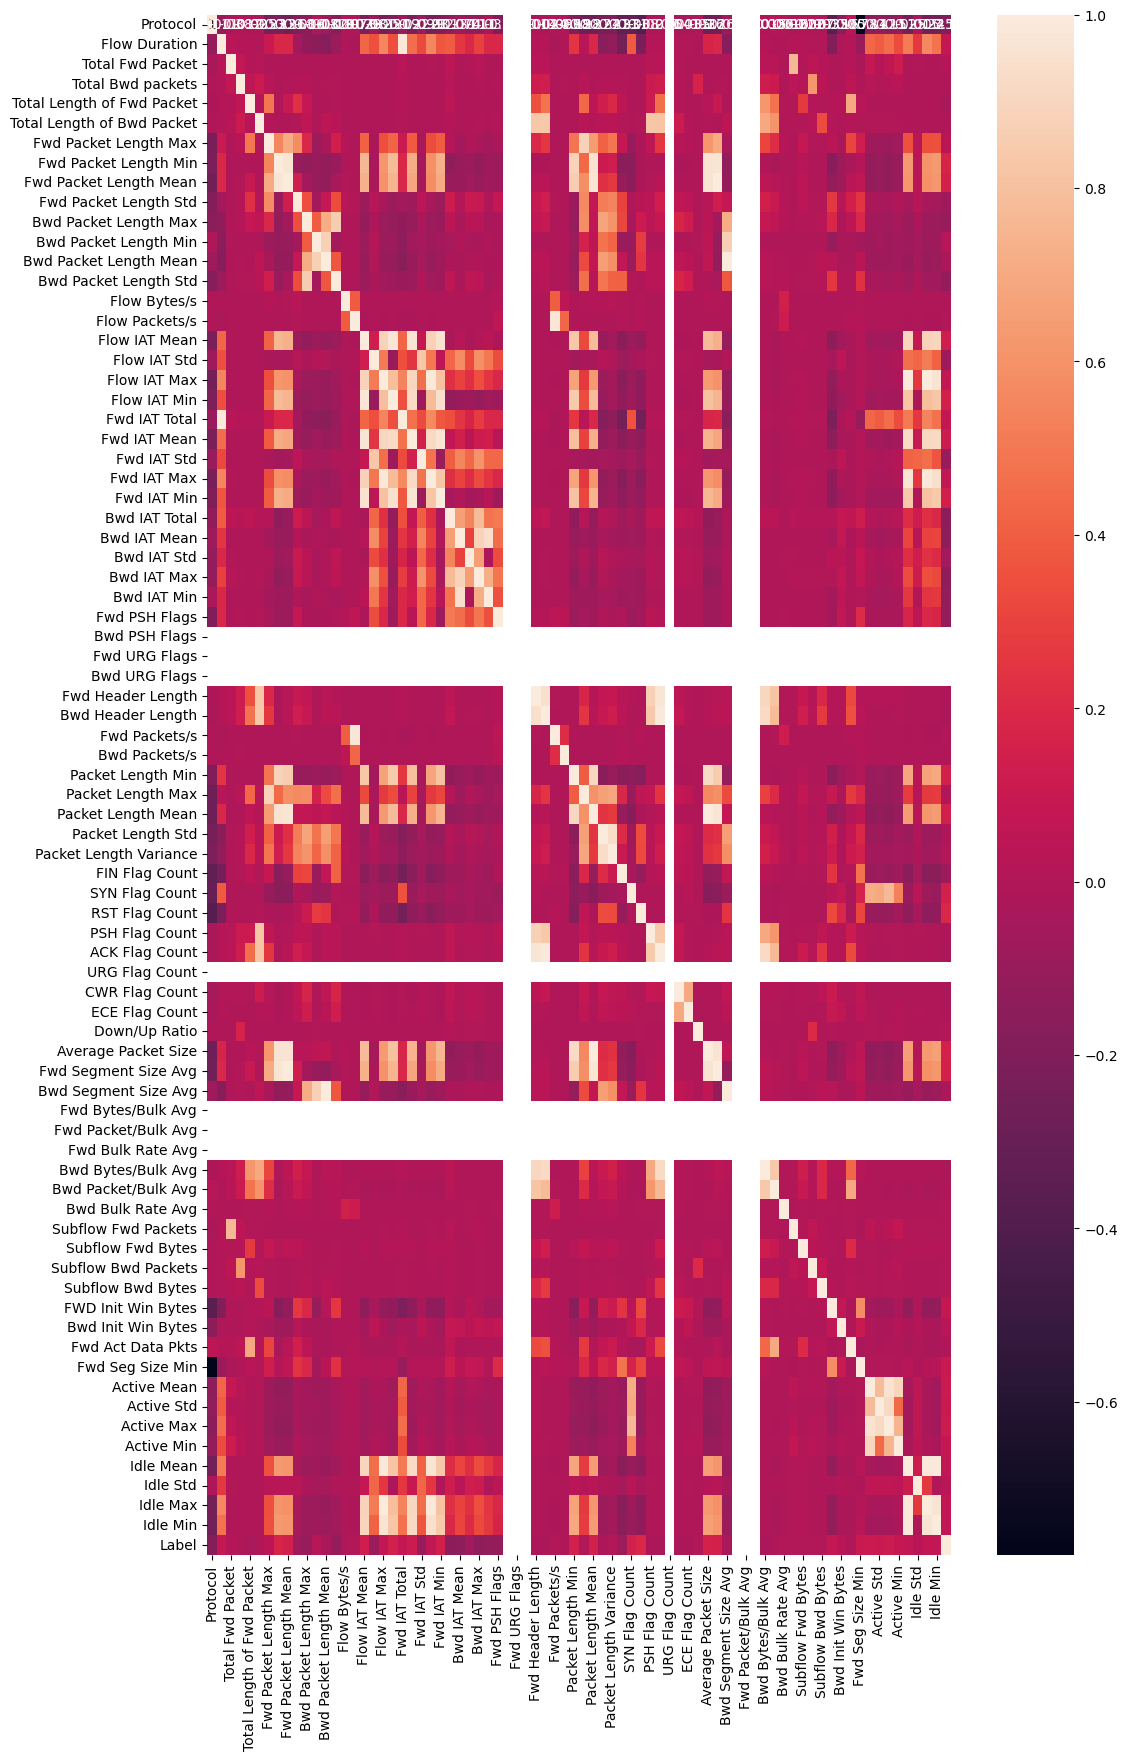

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize = (12, 20))
sns.heatmap(df.corr(), annot=True)
plt.show()

In [17]:
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count',
       

In [18]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [19]:
df2 = df.copy()

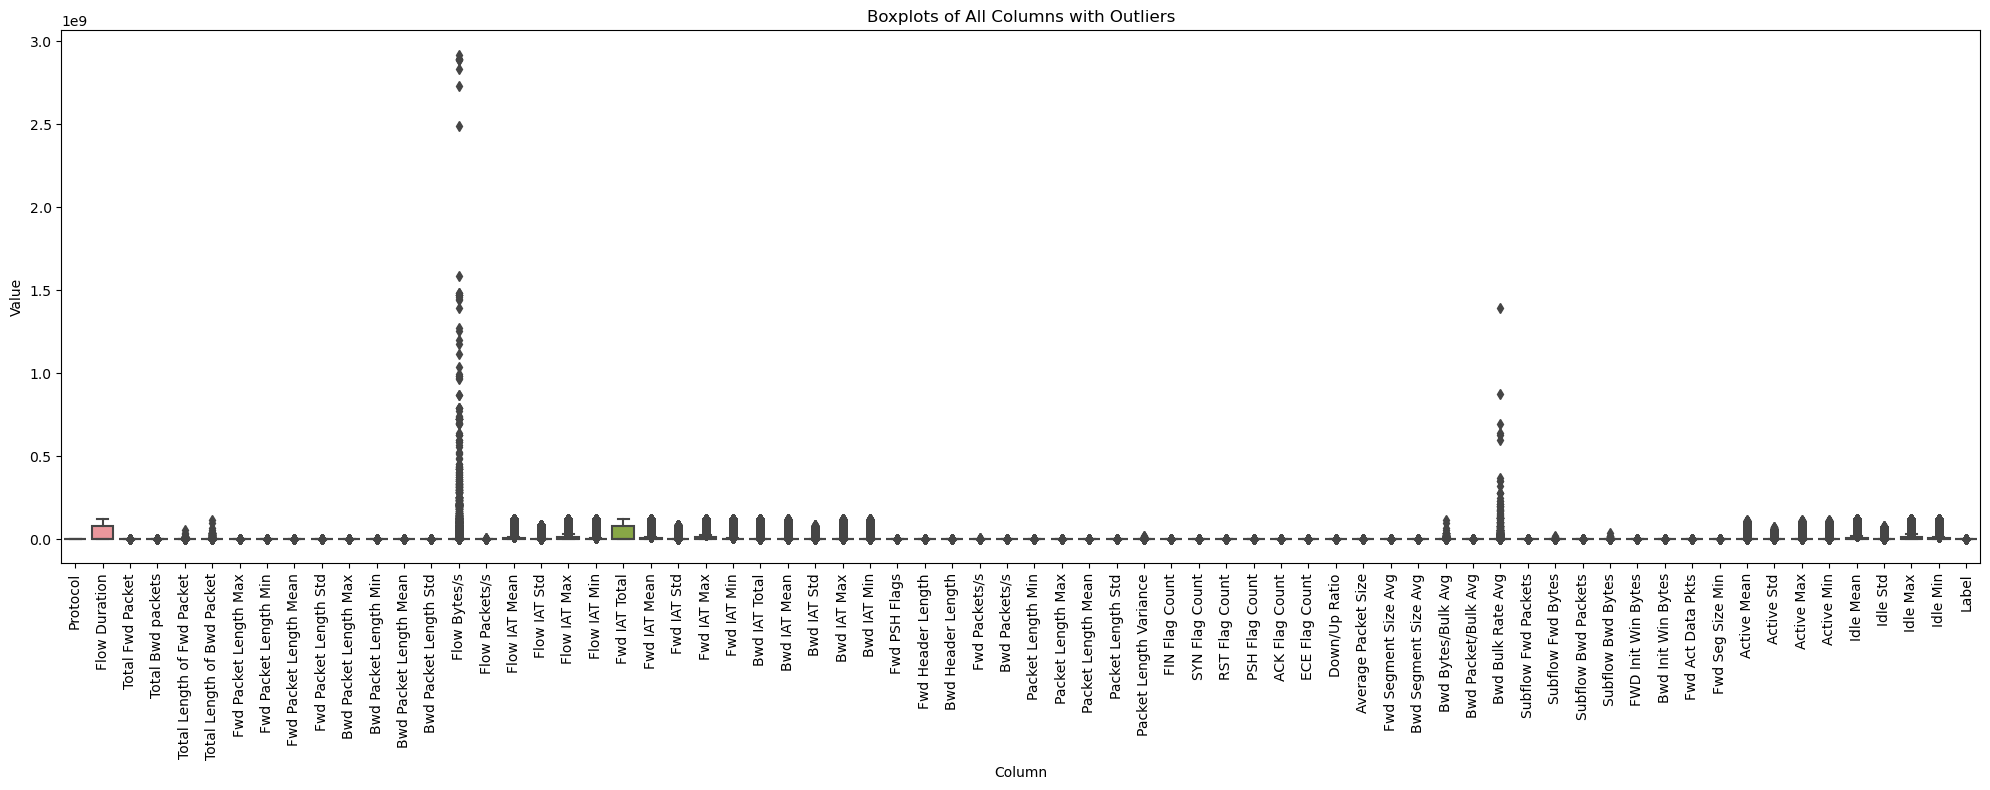

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers.pdf")   # <-- save as PDF
plt.show()

In [21]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [22]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [23]:
outliers_per_column.pop("Label")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 0,
 'Total Fwd Packet': 260322,
 'Total Bwd packets': 153470,
 'Total Length of Fwd Packet': 316514,
 'Total Length of Bwd Packet': 306249,
 'Fwd Packet Length Max': 281495,
 'Fwd Packet Length Min': 294062,
 'Fwd Packet Length Mean': 256900,
 'Fwd Packet Length Std': 399623,
 'Bwd Packet Length Max': 297008,
 'Bwd Packet Length Min': 180297,
 'Bwd Packet Length Mean': 213554,
 'Bwd Packet Length Std': 280113,
 'Flow Bytes/s': 269173,
 'Flow Packets/s': 194913,
 'Flow IAT Mean': 232054,
 'Flow IAT Std': 273983,
 'Flow IAT Max': 315334,
 'Flow IAT Min': 193157,
 'Fwd IAT Total': 0,
 'Fwd IAT Mean': 283450,
 'Fwd IAT Std': 256991,
 'Fwd IAT Max': 315519,
 'Fwd IAT Min': 229249,
 'Bwd IAT Total': 455955,
 'Bwd IAT Mean': 455981,
 'Bwd IAT Std': 380258,
 'Bwd IAT Max': 455983,
 'Bwd IAT Min': 374576,
 'Fwd PSH Flags': 95782,
 'Fwd Header Length': 219957,
 'Bwd Header Length': 292504,
 'Fwd Packets/s': 189889,
 'Bwd Packets/s': 180709,
 'Packet Length Min':

In [24]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

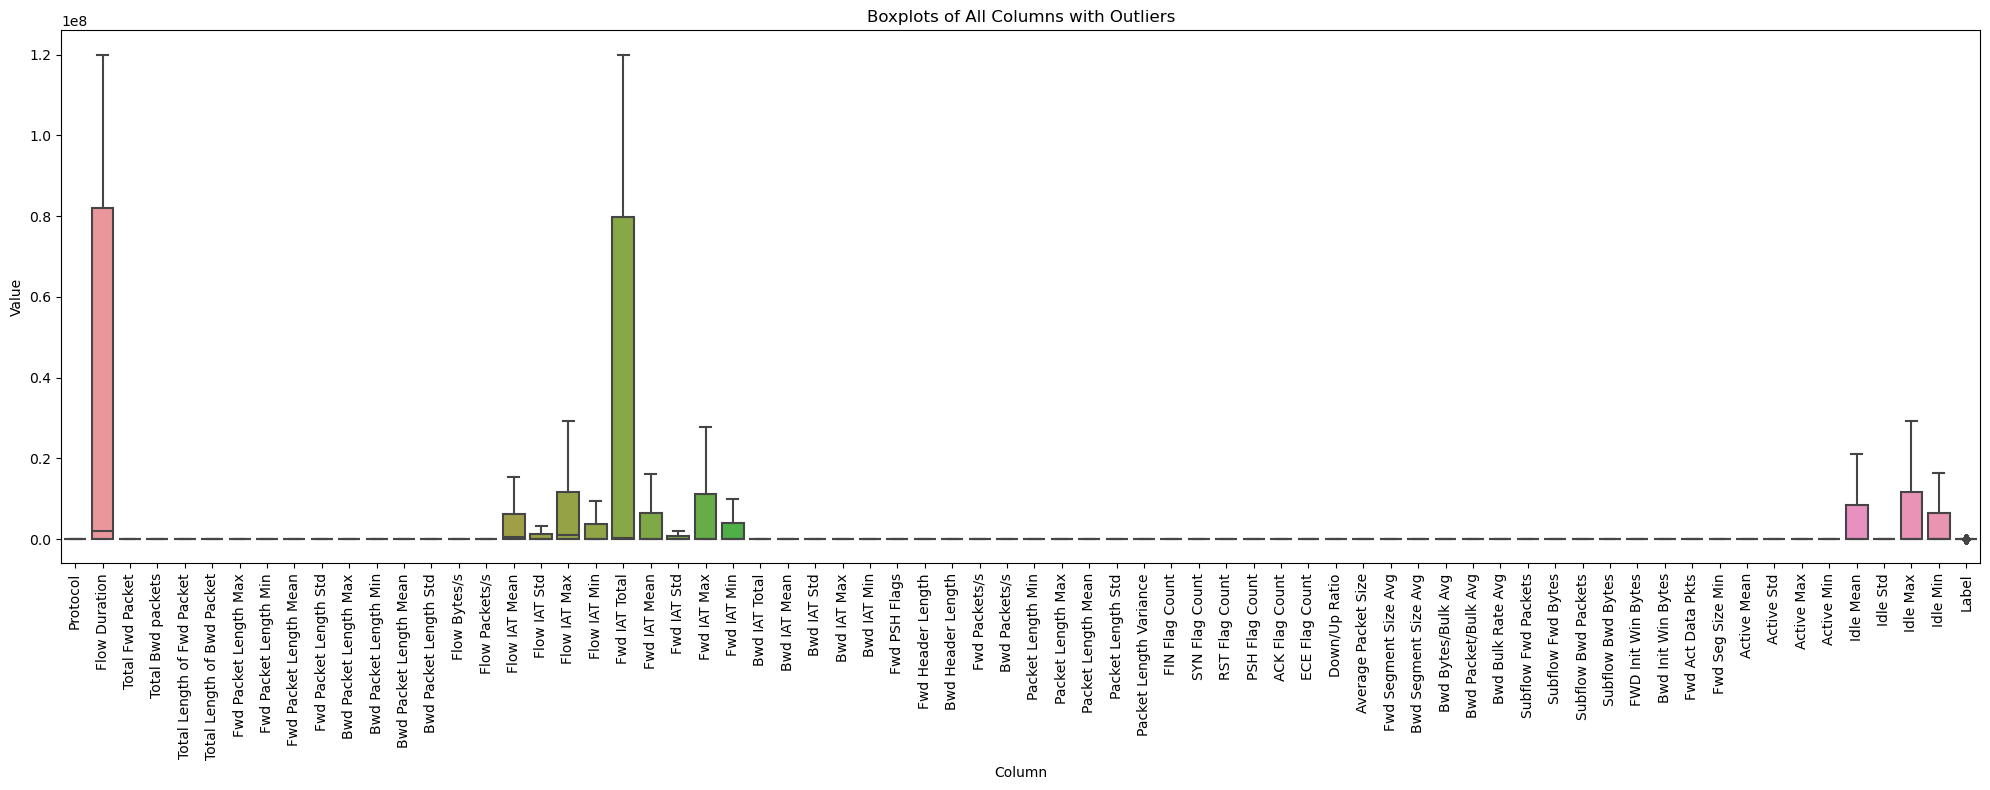

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers-removed.pdf")   # <-- save as PDF
plt.show()

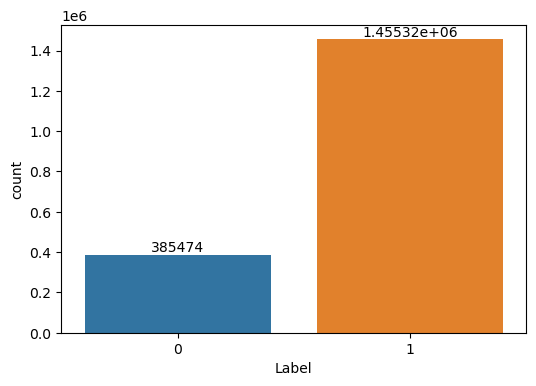

In [26]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x='Label',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [27]:
df2.shape

(1840796, 70)

In [28]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [29]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [30]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Label'])
y = df2['Label']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Label
1    1164257
0     308379
Name: count, dtype: int64
Label
1    1164257
0    1164257
Name: count, dtype: int64


<h2>ML Models</h2>


🔹 Training Logistic Regression...
Logistic Regression Performance:
  Accuracy:  0.7906
  Precision: 0.7422
  Recall:    0.7906
  F1-score:  0.7366

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.12      0.20     77095
           1       0.81      0.97      0.88    291065

    accuracy                           0.79    368160
   macro avg       0.65      0.54      0.54    368160
weighted avg       0.74      0.79      0.74    368160



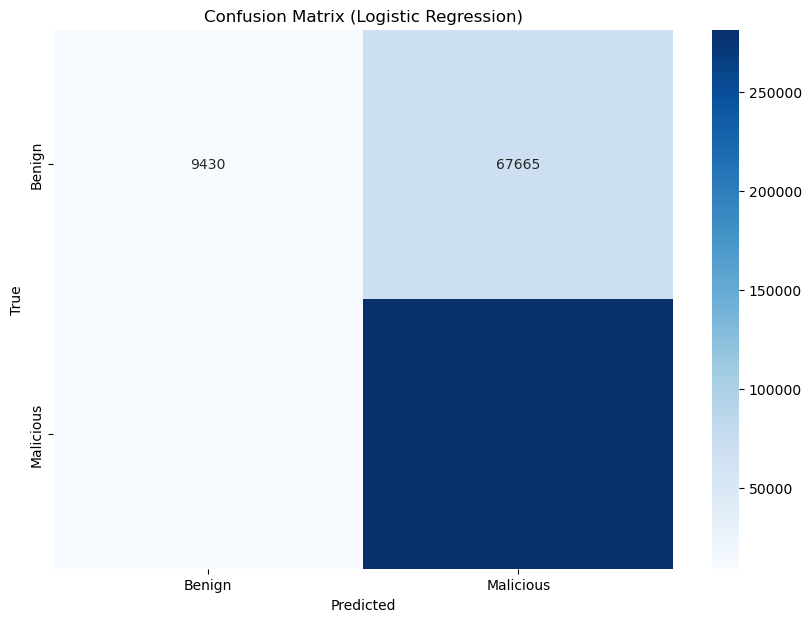


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.8701
  Precision: 0.8701
  Recall:    0.8701
  F1-score:  0.8701

Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.69      0.69     77095
           1       0.92      0.92      0.92    291065

    accuracy                           0.87    368160
   macro avg       0.80      0.80      0.80    368160
weighted avg       0.87      0.87      0.87    368160



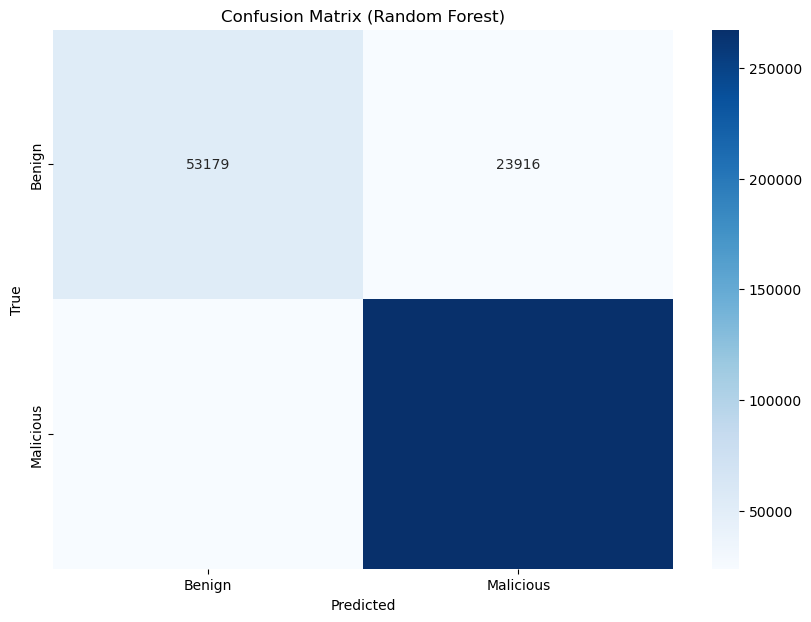


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [16:50:14] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.8729
  Precision: 0.8694
  Recall:    0.8729
  F1-score:  0.8708

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.65      0.68     77095
           1       0.91      0.93      0.92    291065

    accuracy                           0.87    368160
   macro avg       0.81      0.79      0.80    368160
weighted avg       0.87      0.87      0.87    368160



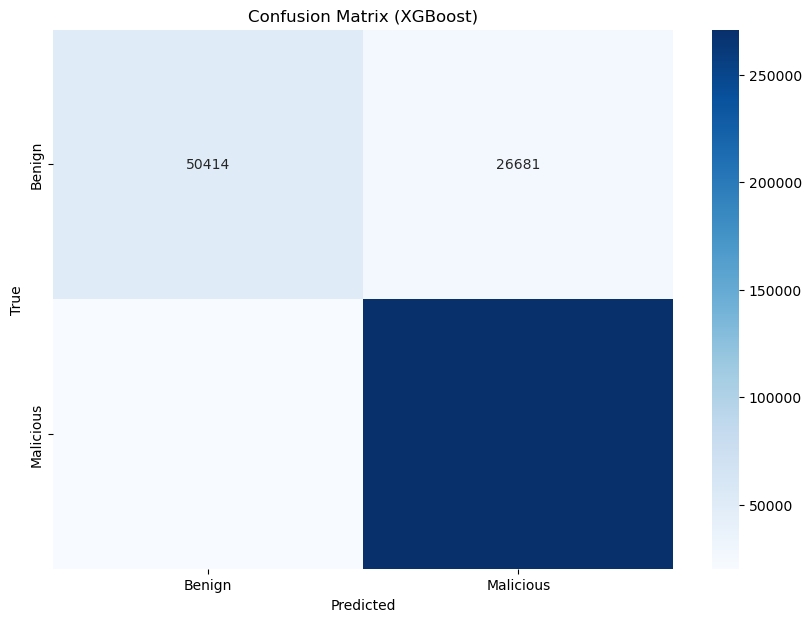


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.8605
  Precision: 0.8609
  Recall:    0.8605
  F1-score:  0.8607

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.67      0.67     77095
           1       0.91      0.91      0.91    291065

    accuracy                           0.86    368160
   macro avg       0.79      0.79      0.79    368160
weighted avg       0.86      0.86      0.86    368160



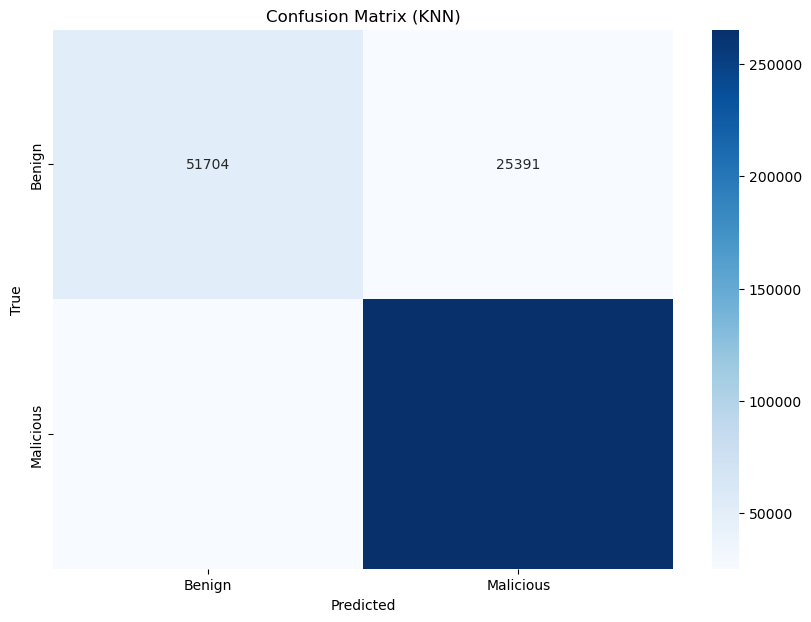


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.6112
  Precision: 0.7718
  Recall:    0.6112
  F1-score:  0.6473

Classification Report:
               precision    recall  f1-score   support

           0       0.32      0.74      0.44     77095
           1       0.89      0.58      0.70    291065

    accuracy                           0.61    368160
   macro avg       0.60      0.66      0.57    368160
weighted avg       0.77      0.61      0.65    368160



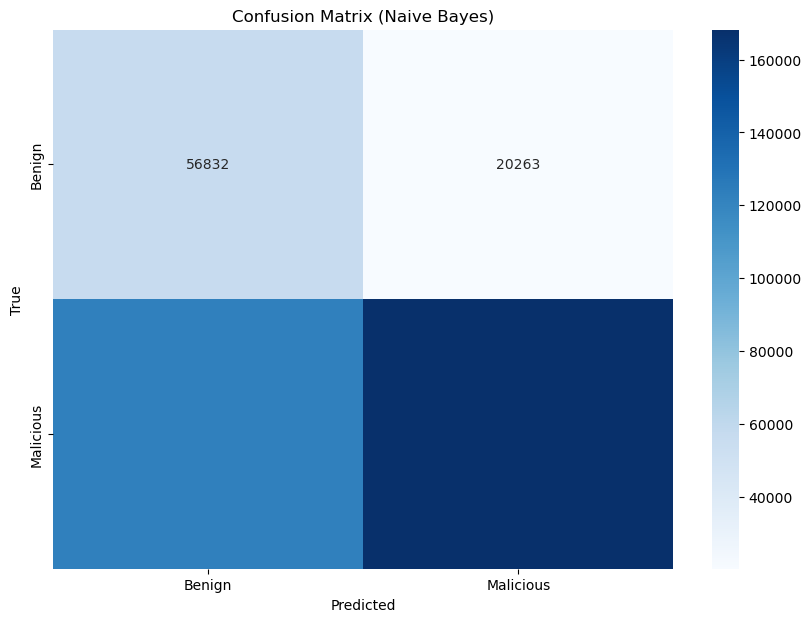


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.8481
  Precision: 0.8484
  Recall:    0.8481
  F1-score:  0.8482

Classification Report:
               precision    recall  f1-score   support

           0       0.64      0.64      0.64     77095
           1       0.90      0.90      0.90    291065

    accuracy                           0.85    368160
   macro avg       0.77      0.77      0.77    368160
weighted avg       0.85      0.85      0.85    368160



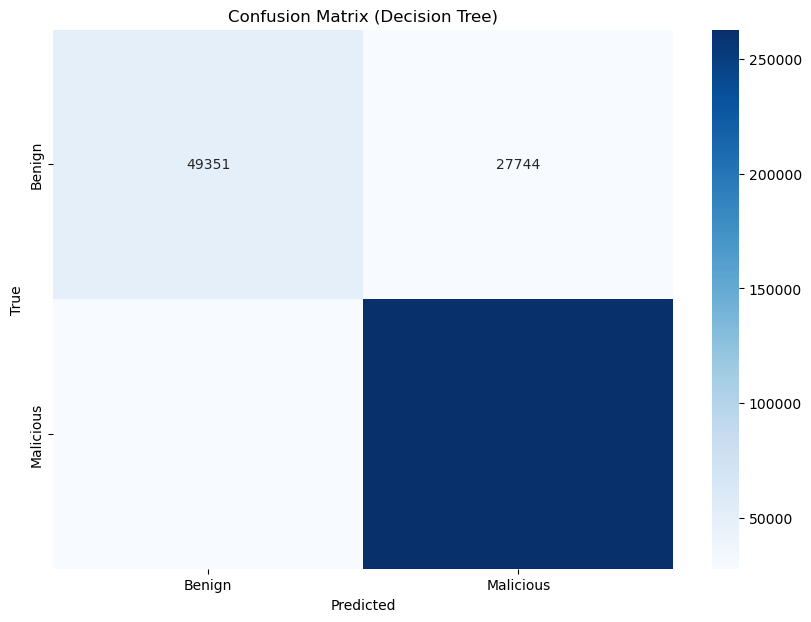


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.7906
  Precision: 0.6250
  Recall:    0.7906
  F1-score:  0.6981


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize


Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00     77095
           1       0.79      1.00      0.88    291065

    accuracy                           0.79    368160
   macro avg       0.40      0.50      0.44    368160
weighted avg       0.63      0.79      0.70    368160



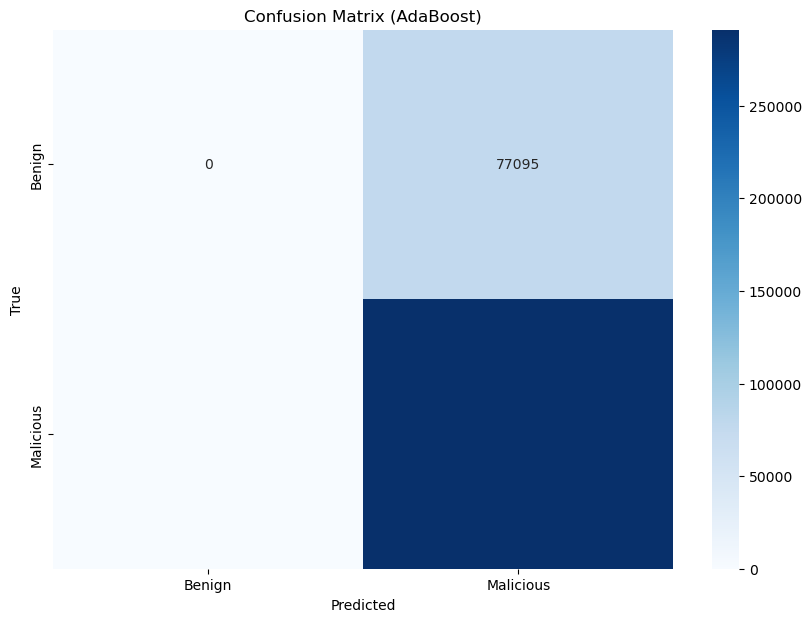


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.8640
  Precision: 0.8645
  Recall:    0.8640
  F1-score:  0.8642

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.68      0.68     77095
           1       0.91      0.91      0.91    291065

    accuracy                           0.86    368160
   macro avg       0.79      0.80      0.80    368160
weighted avg       0.86      0.86      0.86    368160



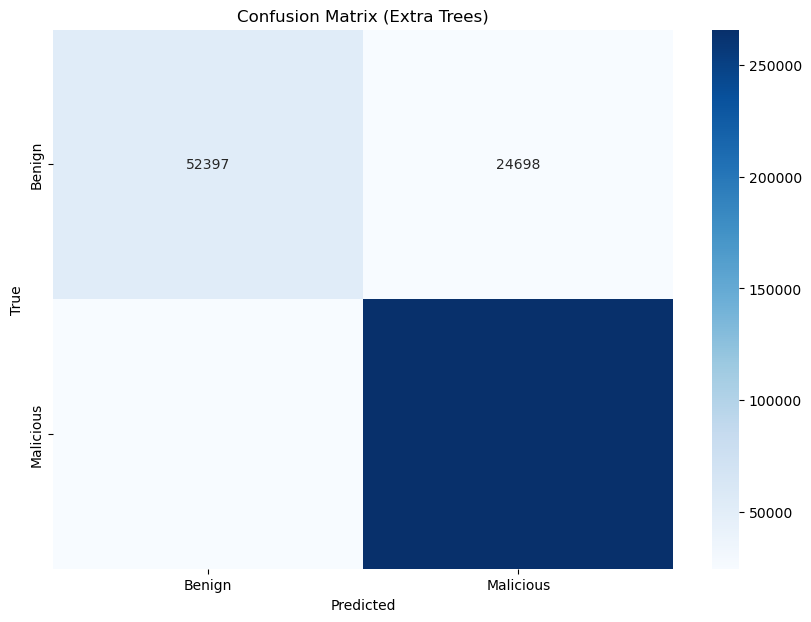


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.8730
  Precision: 0.8699
  Recall:    0.8730
  F1-score:  0.8712

Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.66      0.68     77095
           1       0.91      0.93      0.92    291065

    accuracy                           0.87    368160
   macro avg       0.81      0.79      0.80    368160
weighted avg       0.87      0.87      0.87    368160



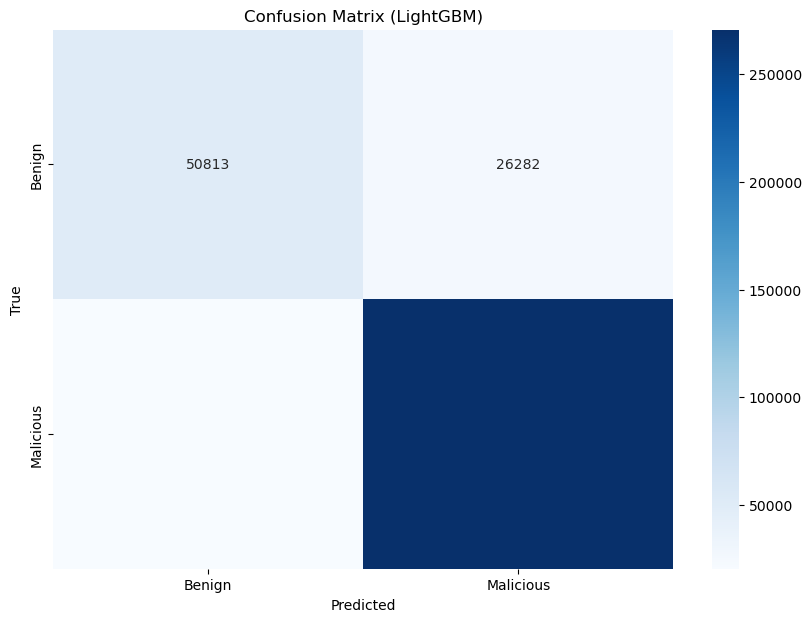


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.8618
  Precision: 0.8576
  Recall:    0.8618
  F1-score:  0.8593

Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.62      0.65     77095
           1       0.90      0.92      0.91    291065

    accuracy                           0.86    368160
   macro avg       0.79      0.77      0.78    368160
weighted avg       0.86      0.86      0.86    368160



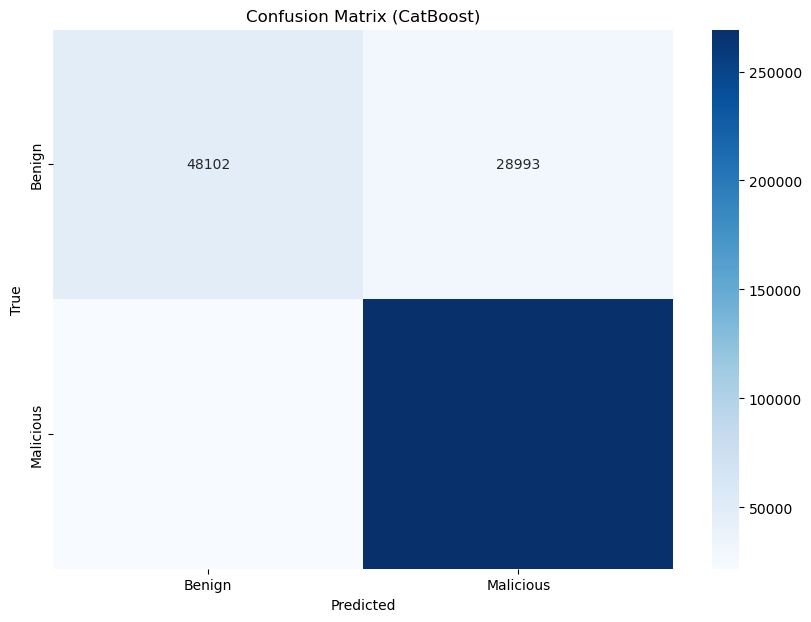


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.790610   0.742182  0.790610  0.736582
Random Forest        0.870067   0.870070  0.870067  0.870069
XGBoost              0.872865   0.869381  0.872865  0.870750
KNN                  0.860482   0.860873  0.860482  0.860675
Naive Bayes          0.611237   0.771820  0.611237  0.647312
Decision Tree        0.848058   0.848386  0.848058  0.848221
AdaBoost             0.790594   0.625038  0.790594  0.698135
Extra Trees          0.864024   0.864459  0.864024  0.864238
LightGBM             0.873023   0.869885  0.873023  0.871162
CatBoost             0.861767   0.857612  0.861767  0.859265


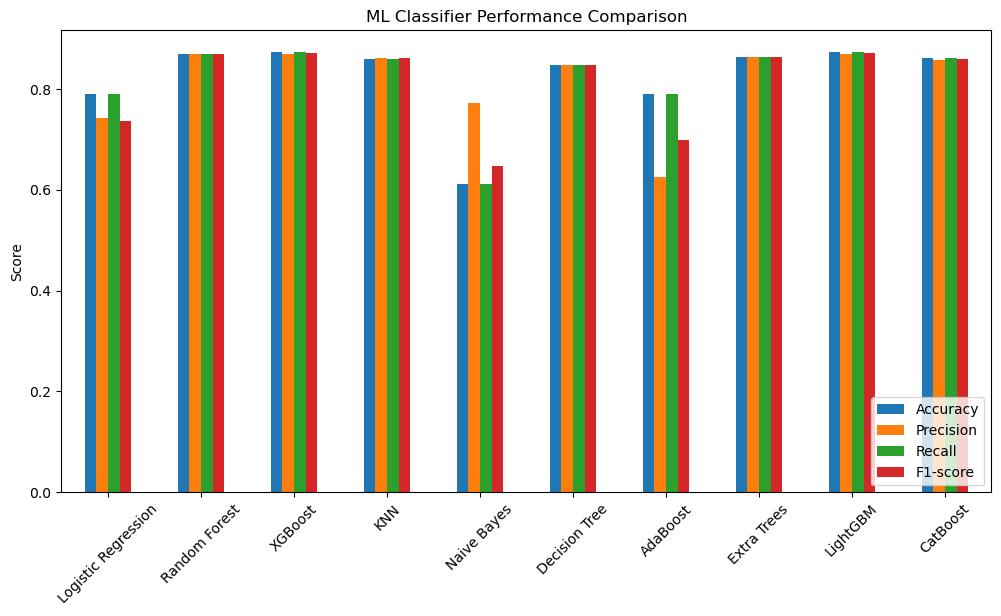

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = ['Benign', 'Malicious']

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"Graphs/Binary-ml-{name}.pdf")   # <-- save as PDF
    plt.show()

# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...
Logistic Regression Avg Performance:
  Accuracy:  0.7904
  Precision: 0.7416
  Recall:    0.7904
  F1-score:  0.7361

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.8702
  Precision: 0.8702
  Recall:    0.8702
  F1-score:  0.8702

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:48:10] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:48:32] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:49:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:49:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.8729
  Precision: 0.8699
  Recall:    0.8729
  F1-score:  0.8711

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.8606
  Precision: 0.8610
  Recall:    0.8606
  F1-score:  0.8608

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.6132
  Precision: 0.7726
  Recall:    0.6132
  F1-score:  0.6491

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.8408
  Precision: 0.8429
  Recall:    0.8408
  F1-score:  0.8418

🔹 Training Gradient Boosting with 5-Fold Cross Validation...
Gradient Boosting Avg Performance:
  Accuracy:  0.8480
  Precision: 0.8393
  Recall:    0.8480
  F1-score:  0.8417

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.7906
  Precision: 0.6250
  Recall:    0.7906
  F1-score:  0.6981

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Perf

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.8733
  Precision: 0.8702
  Recall:    0.8733
  F1-score:  0.8715

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.8620
  Precision: 0.8567
  Recall:    0.8620
  F1-score:  0.8586

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.790426   0.741628  0.790426  0.736125
Random Forest        0.870227   0.870175  0.870227  0.870200
XGBoost              0.872858   0.869877  0.872858  0.871106
KNN                  0.860629   0.861019  0.860629  0.860821
Naive Bayes          0.613210   0.772602  0.613210  0.649124
Decision Tree        0.840843   0.842873  0.840843  0.841761
Gradient Boosting    0.848026   0.839325  0.848026  0.841688
AdaBoost             0.790594   0.625039  0.790594  0.698136
Extra Trees          0.864224   0.864498  0.864224  0.864359
LightGBM             0.873281   0.870229  0.873281  0.871470
CatBoost             0.862048 

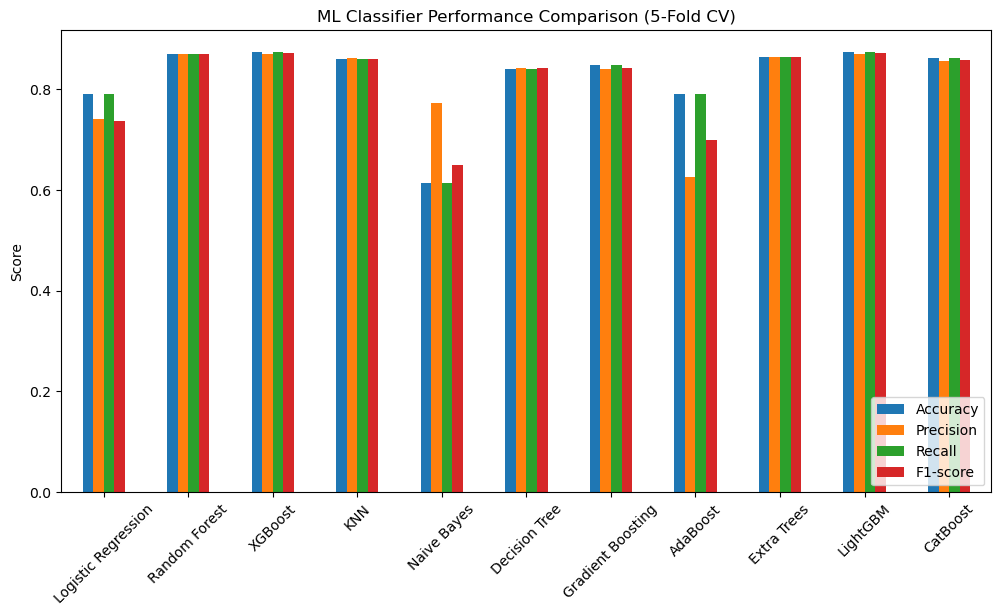

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, 
                             use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"Graphs/Binary-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare-5fold.pdf")
plt.show()
